In [1]:
import glob
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cmocean
import numpy as np
import xarray as xr

import rioxarray
import rasterio
import datacube
from datacube.utils.cog import write_cog

In [2]:
variables_dict = {
    'cherry-fruit-cracking-days': ('cherry-fruit-cracking-days-at-maturity', 'days'),
    'general-average-summer-temperature': ('tavg', 'tavg'),
    'general-average-winter-temperature': ('tavg', 'tavg'),
#    'general-drought-baseline-thresholds': '',
    'general-drought-intensity': ('drought_intensity', 'drought_intensity'),
#    'general-historical-drought-events': '',
#    'general-historical-hot-dry-events': '',
    'general-hot-days': ('general-hot-days', 'days'),
#	'general-hot-dry-events-baseline-thresholds': '',
	'general-time-in-drought': ('time_in_drought', 'time_in_drought'),
	'general-time-in-hot-dry-events': ('time_in_hot_dry_events', 'time_hot_dry_events'),
	'mango-wet-days-at-harvest': ('mango-wet-days-at-harvest', 'days'),
	'northern-beef-dry-season-rainfall': ('agcd-precip', 'agcd-precip'),
	'northern-beef-wet-season-rainfall': ('agcd-precip', 'agcd-precip'),
	'potato-frost-days-at-tuber-initiation': ('potato-frost-days-at-tuber-initiation', 'days'),
# summer reference evapotranspiration?
}
                         
cmip6_to_cmip5_experiment = {}
cmip6_to_cmip5_experiment['ssp245'] = 'rcp45'
cmip6_to_cmip5_experiment['ssp370'] = 'rcp85'

In [5]:
def add_diff_attrs(da, variable):
    """Add metadata attributes to the difference in change category data"""

    da['lat'].attrs['long_name'] = 'latitude'
    da['lat'].attrs['units'] = 'degrees_north'
    da['lon'].attrs['long_name'] = 'longitude'
    da['lon'].attrs['units'] = 'degrees_east'
    da.attrs['standard_name'] = 'difference_in_change_category'
    da.attrs['long_name'] = 'difference in the approximate change by 2050s category (-1=decrease;0=inconclusive/minimal;1=increase) between CMIP6 (ssp245) and CMIP5 (rcp45)'
    da.attrs['variable'] = variable
    da.rio.write_crs("EPSG:4326", inplace=True)

    return da
    

def plot_change_cat(variable, write_cog_file=False):
    """Plot the change category."""
    
    data_dir = '/Volumes/{d61-csa-p2}/work/CSA/Science/Data/cmip6-transition-data'
    cmip5_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip5-change-cat.nc')[0]
    cmip6_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip6-change-cat.nc')[0]
    cmip5_da = xr.open_dataset(cmip5_file, decode_times=False)['change-cat']
    cmip6_da = xr.open_dataset(cmip6_file, decode_times=False)['change-cat']

    cmip6_cat = xr.where(cmip6_da == 2, -1, cmip6_da)
    cmip5_cat = xr.where(cmip5_da == 2, -1, cmip5_da)    
    diff_cat = cmip6_cat - cmip5_cat

    if write_cog_file:
        diff_cat = add_diff_attrs(diff_cat, variable)
        outfile = cmip5_file.split('/')[-1].replace('cmip5-change-cat', 'cmip6-minus-cmip5-change-cat')
        outfile = outfile.replace('.nc', '.tif')
        write_cog(geo_im=diff_cat, fname=outfile, overwrite=True)
        print(outfile)
    
    fig = plt.figure(figsize=[10, 5])
    cbar_pad = 0.04
    
    ax1 = fig.add_subplot(131, projection=ccrs.PlateCarree())
    cmip5_obj = cmip5_cat.plot(
        ax=ax1,
        transform=ccrs.PlateCarree(),
        levels=[-1.5, -0.5, 0.5, 1.5],
        cbar_kwargs={'location': 'bottom', 'pad': cbar_pad, 'label': None},
    )
    ax1.set_title('CMIP5')
    cmip5_cbar = cmip5_obj.colorbar
    cmip5_cbar.set_ticks([-1, 0, 1], labels=['decrease', 'minimal', 'increase'])
    
    ax2 = fig.add_subplot(132, projection=ccrs.PlateCarree())
    cmip6_obj = cmip6_cat.plot(
        ax=ax2,
        transform=ccrs.PlateCarree(),
        levels=[-1.5, -0.5, 0.5, 1.5],
        cbar_kwargs={'location': 'bottom', 'pad': cbar_pad, 'label': None},
    )
    ax2.set_title('CMIP6')
    cmip6_cbar = cmip6_obj.colorbar
    cmip6_cbar.set_ticks([-1, 0, 1], labels=['decrease', 'minimal', 'increase'])
    
    ax3 = fig.add_subplot(133, projection=ccrs.PlateCarree())
    diff_obj = diff_cat.plot(
        ax=ax3,
        transform=ccrs.PlateCarree(),
        levels=[-2.5, -1.5, -0.5, 0.5, 1.5, 2.5],
        cmap='RdBu_r',
        cbar_kwargs={'location': 'bottom', 'pad': cbar_pad, 'label': 'Difference'},
    )
    ax3.set_title('Difference (CMIP6 - CMIP5)')
    diff_cbar = diff_obj.colorbar
    diff_cbar.set_ticks([-2, -1, 0, 1, 2])

    for ax in [ax1, ax2, ax3]:
        ax.coastlines()
        ax.add_feature(cartopy.feature.STATES)
    
    plt.suptitle(variable, y=0.85)
    plt.tight_layout()
    plt.show()

    return diff_cat

cherry-fruit-cracking-days-at-maturity-cmip6-minus-cmip5-change-cat.tif


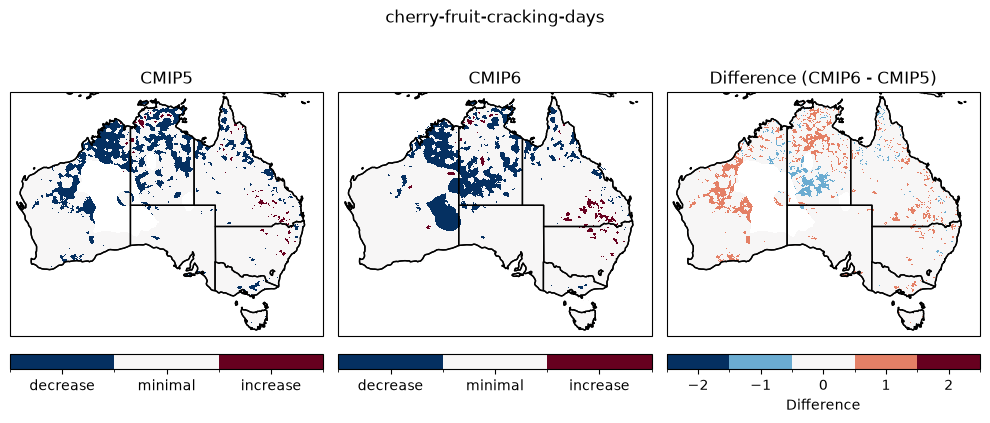

general-average-summer-temperature-cmip6-minus-cmip5-change-cat.tif


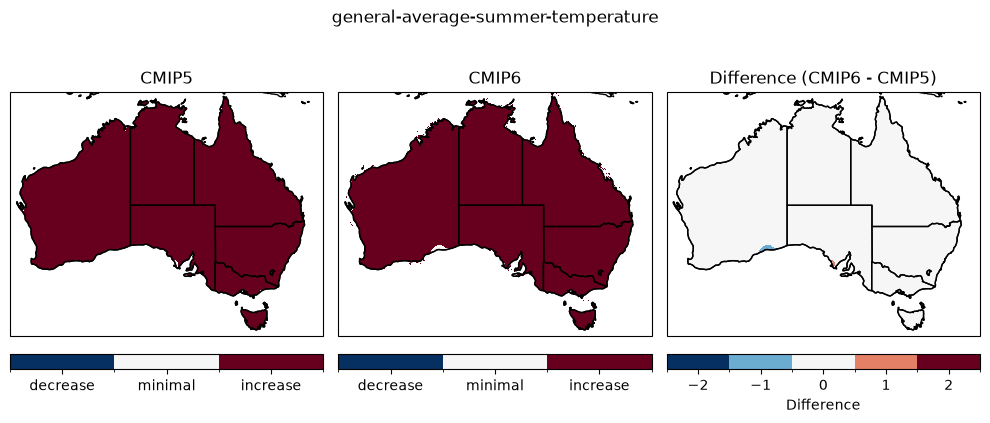

general-average-winter-temperature-cmip6-minus-cmip5-change-cat.tif


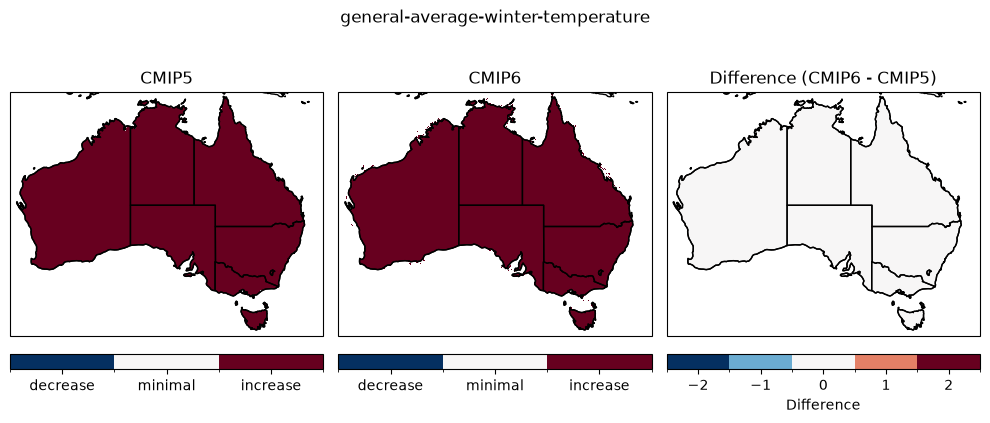

general-drought-intensity-cmip6-minus-cmip5-change-cat.tif


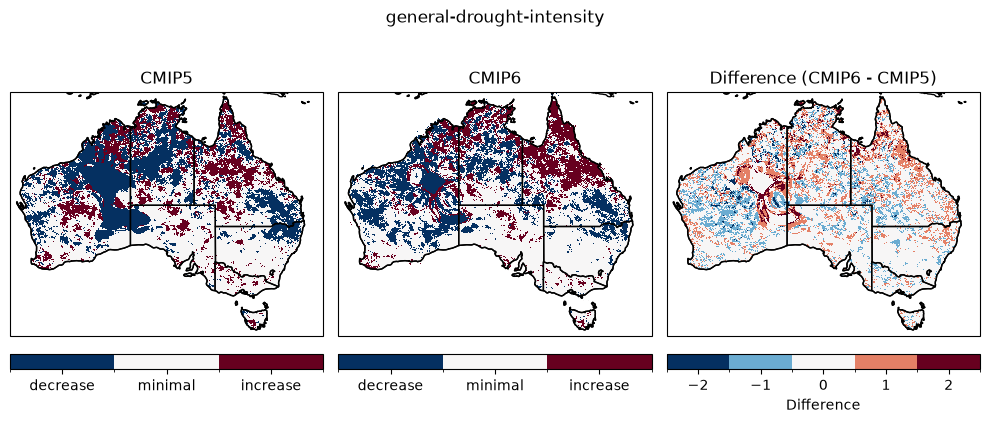

general-hot-days-cmip6-minus-cmip5-change-cat.tif


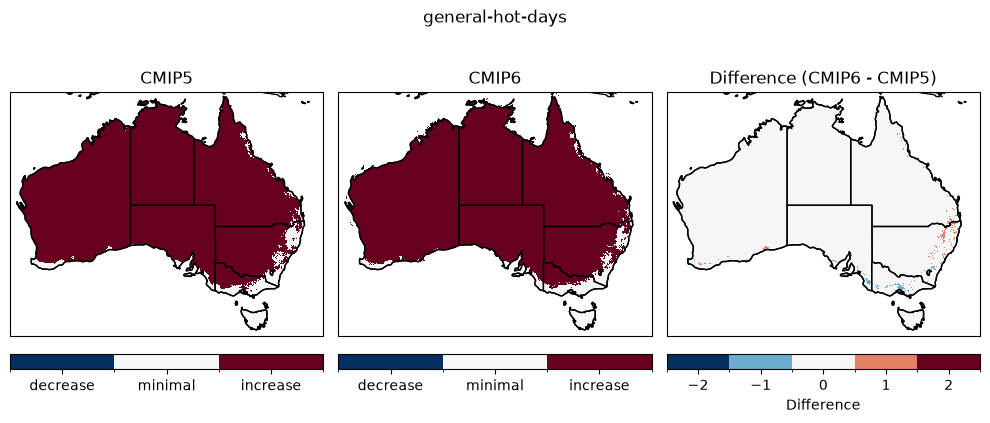

general-time-in-drought-cmip6-minus-cmip5-change-cat.tif


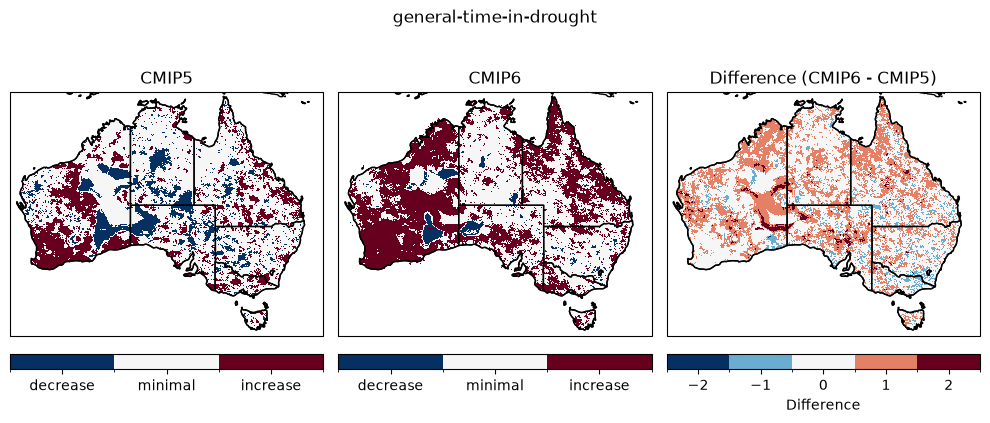

general-time-in-hot-dry-events-cmip6-minus-cmip5-change-cat.tif


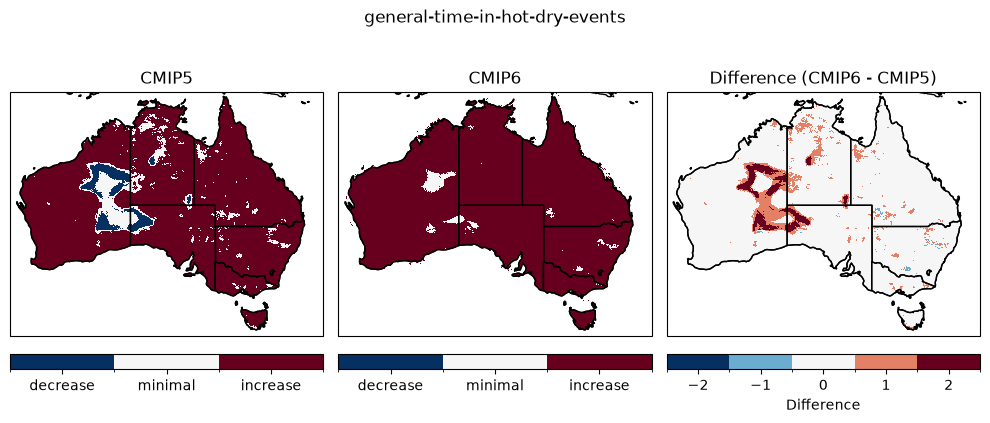

mango-wet-days-at-harvest-cmip6-minus-cmip5-change-cat.tif


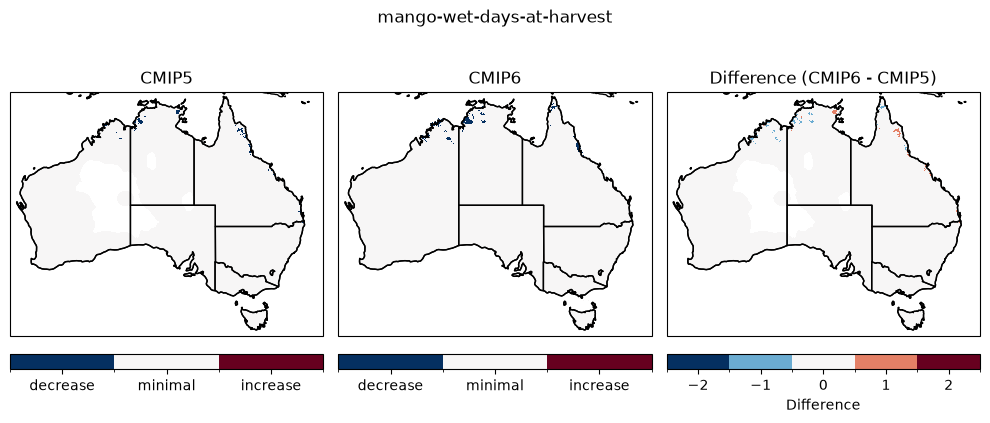

northern-beef-dry-season-rainfall-cmip6-minus-cmip5-change-cat.tif


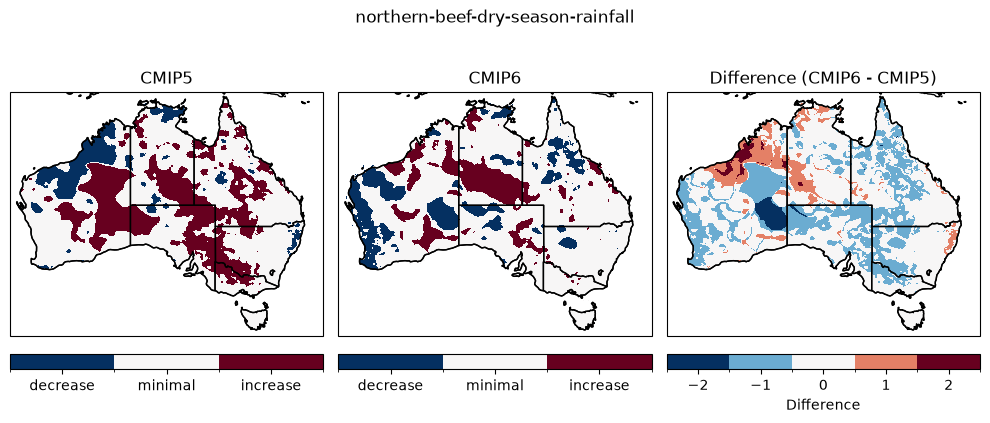

northern-beef-wet-season-rainfall-cmip6-minus-cmip5-change-cat.tif


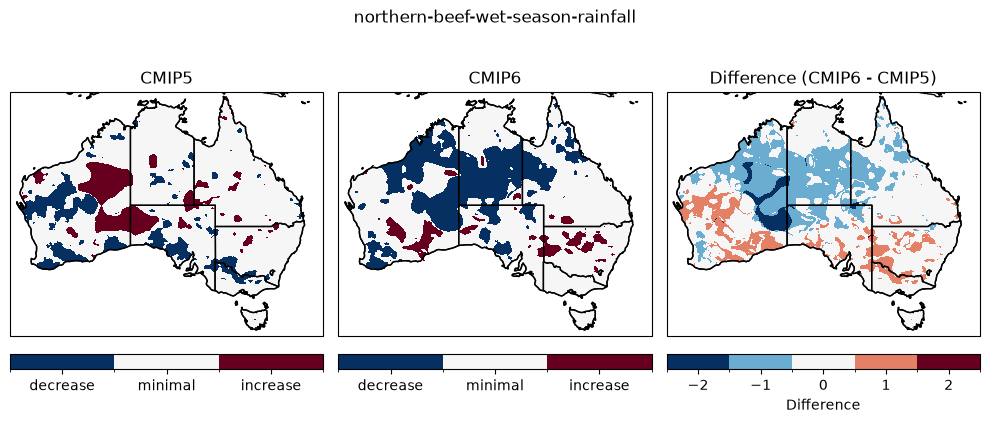

potato-frost-days-at-tuber-initiation-cmip6-minus-cmip5-change-cat.tif


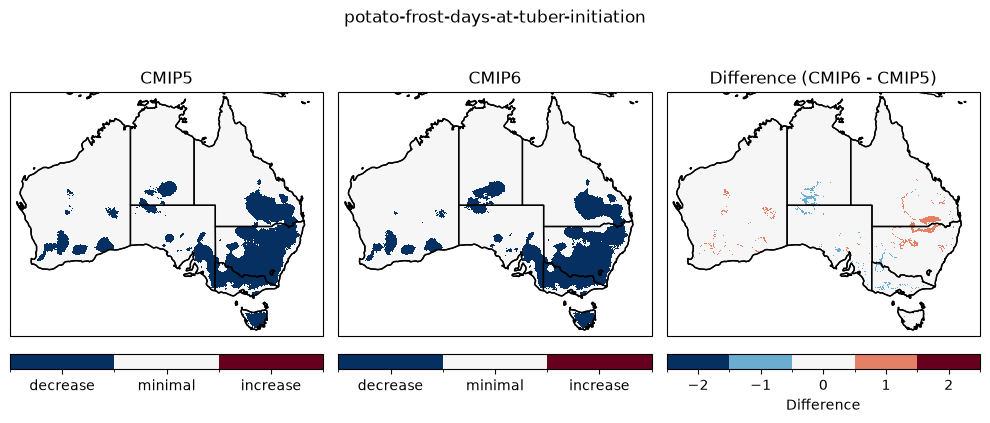

In [4]:
for variable in variables_dict.keys():
    plot_change_cat(variable, write_cog_file=True)

In [5]:
def plot_comparison(variable, cmip6_exp, var_levels, diff_levels, cmap, extend='neither'):
    """Plot comparison between CMIP6 and CMIP5"""

    future_var, base_var = variables_dict[variable]
    cmip5_exp = cmip6_to_cmip5_experiment[cmip6_exp]
    
    data_dir = '/Volumes/{d61-csa-p2}/work/CSA/Science/Data/cmip6-transition-data/'
    if variable in ['general-drought-intensity', 'general-time-in-drought', 'general-time-in-hot-dry-events']:
        cmip6_base_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*1996-2025-with-cmip6-baseline-1985-2014.nc')[0]
        cmip5_base_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*1996-2025-with-cmip5-baseline-1986-2005.nc')[0]
        cmip6_base_da = xr.open_dataset(cmip6_base_file, decode_times=False)[base_var]
        cmip5_base_da = xr.open_dataset(cmip5_base_file, decode_times=False)[base_var]
    else:
        base_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*1996-2025-avg.nc')[0]
        cmip6_base_da = xr.open_dataset(base_file, decode_times=False)[base_var]
        cmip5_base_da = cmip6_base_da
    cmip6_mid_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip6-2035-2064-{cmip6_exp}*mmm-avg.nc')[0]
    cmip5_mid_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip5-2036-2065-{cmip5_exp}*mmm-avg.nc')[0]
    cmip6_late_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip6-2070-2099-{cmip6_exp}*mmm-avg.nc')[0]
    cmip5_late_file = glob.glob(f'{data_dir}/{variable}/netcdf/{variable}*cmip5-2056-2085-{cmip5_exp}*mmm-avg.nc')[0]

    cmip6_future_var = future_var
    if variable in ['northern-beef-dry-season-rainfall', 'northern-beef-wet-season-rainfall']:
        cmip5_future_var = 'precip'
    else:
        cmip5_future_var = future_var
    cmip6_mid_da = xr.open_dataset(cmip6_mid_file, decode_times=False)[cmip6_future_var]
    cmip5_mid_da = xr.open_dataset(cmip5_mid_file, decode_times=False)[cmip5_future_var]
    cmip6_late_da = xr.open_dataset(cmip6_late_file, decode_times=False)[cmip6_future_var]
    cmip5_late_da = xr.open_dataset(cmip5_late_file, decode_times=False)[cmip5_future_var]

    cmip6_mid_change_da = cmip6_mid_da - cmip6_base_da
    cmip5_mid_change_da = cmip5_mid_da - cmip5_base_da
    cmip6_late_change_da = cmip6_late_da - cmip6_base_da
    cmip5_late_change_da = cmip5_late_da - cmip5_base_da
    diff_mid_change_da = cmip6_mid_change_da - cmip5_mid_change_da
    diff_late_change_da = cmip6_late_change_da - cmip5_late_change_da
    
    fig = plt.figure(figsize=[10, 10])
    
    units = cmip6_mid_da.attrs['units']
    cbar_pad = 0.04
    
    ax1 = fig.add_subplot(231, projection=ccrs.PlateCarree())
    cmip5_mid_change_da.plot(
        ax=ax1,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': f'projected change ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax1.set_title(f'CMIP5 (2036-2065, {cmip5_exp})')
    
    ax2 = fig.add_subplot(232, projection=ccrs.PlateCarree())
    cmip6_mid_change_da.plot(
        ax=ax2,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': f'projected change ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax2.set_title(f'CMIP6 (2035-2064, {cmip6_exp})')
    
    ax3 = fig.add_subplot(233, projection=ccrs.PlateCarree())
    diff_mid_change_da.plot(
        ax=ax3,
        transform=ccrs.PlateCarree(),
        levels=diff_levels,
        extend='both',
        cmap='RdBu_r',
        cbar_kwargs={'label': f'difference ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax3.set_title('Difference (CMIP6 - CMIP5)')

    ax4 = fig.add_subplot(234, projection=ccrs.PlateCarree())
    cmip5_late_change_da.plot(
        ax=ax4,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': f'projected change ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax4.set_title(f'CMIP5 (2056-2085, {cmip5_exp})')
    
    ax5 = fig.add_subplot(235, projection=ccrs.PlateCarree())
    cmip6_late_change_da.plot(
        ax=ax5,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': f'projected change ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax5.set_title(f'CMIP6 (2070-2099, {cmip6_exp})')
    
    ax6 = fig.add_subplot(236, projection=ccrs.PlateCarree())
    diff_late_change_da.plot(
        ax=ax6,
        transform=ccrs.PlateCarree(),
        levels=diff_levels,
        extend='both',
        cmap='RdBu_r',
        cbar_kwargs={'label': f'difference ({units})', 'location': 'bottom', 'pad': cbar_pad},
    )
    ax6.set_title('Difference (CMIP6 - CMIP5)')
    
    for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
        ax.coastlines()
        ax.add_feature(cartopy.feature.STATES)
    #    gls = ax.gridlines(linestyle="--", draw_labels=True)
    #    gls.top_labels = False
    #    gls.right_labels = False
    #    ax.tick_params(axis='y', labelleft=False)

    fig.subplots_adjust(hspace=0) 
    plt.suptitle(f'{variable} (multi-model mean)', y=0.85)
    plt.tight_layout()
    plt.show()

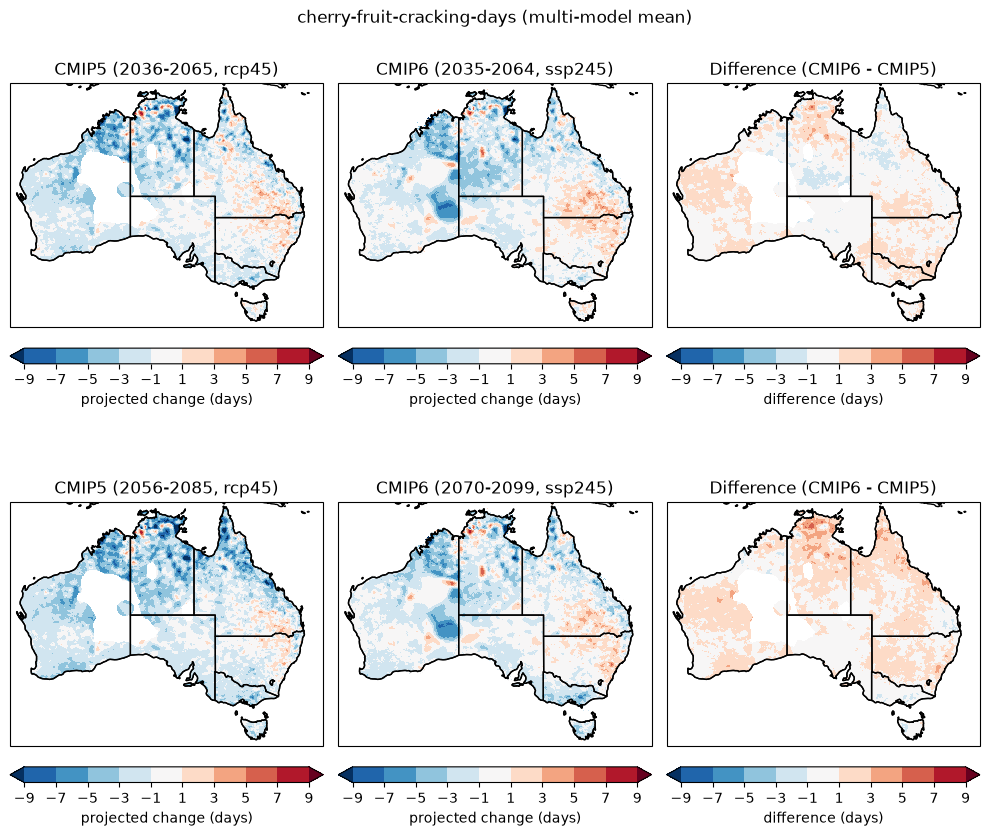

In [7]:
plot_comparison(
    'cherry-fruit-cracking-days',
    'ssp245',
    np.arange(-9, 10, 2),
    np.arange(-9, 10, 2),
    'RdBu_r',
    extend='both',
)

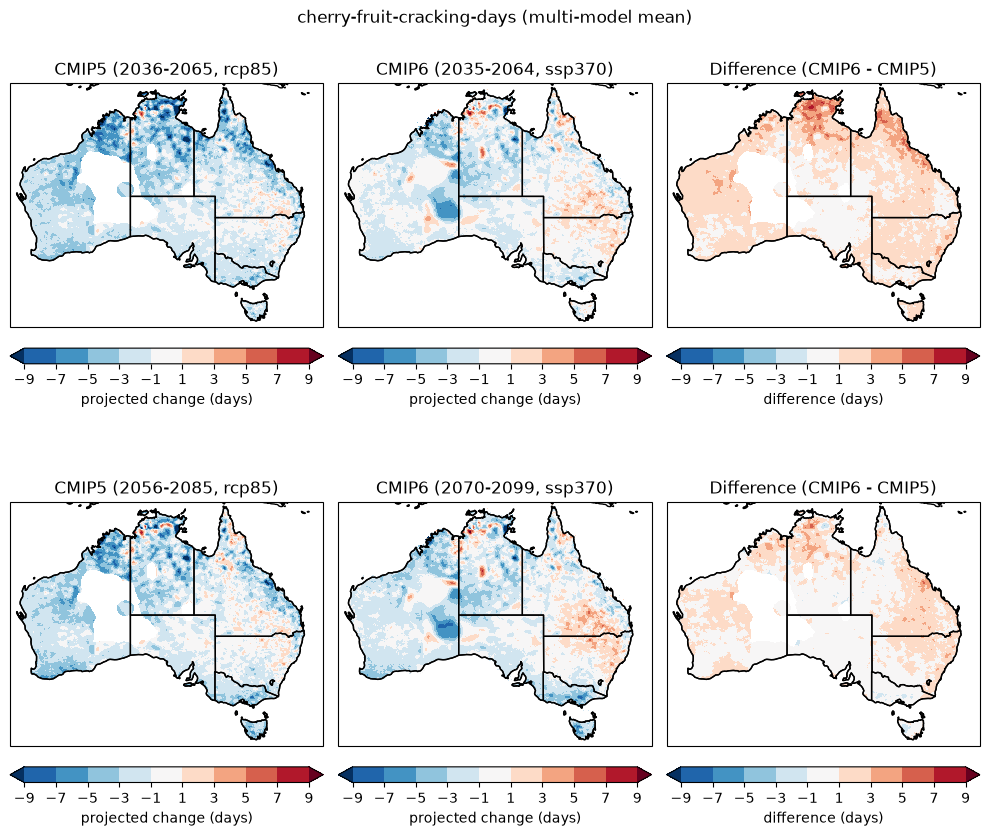

In [6]:
plot_comparison(
    'cherry-fruit-cracking-days',
    'ssp370',
    np.arange(-9, 10, 2),
    np.arange(-9, 10, 2),
    'RdBu_r',
    extend='both',
)

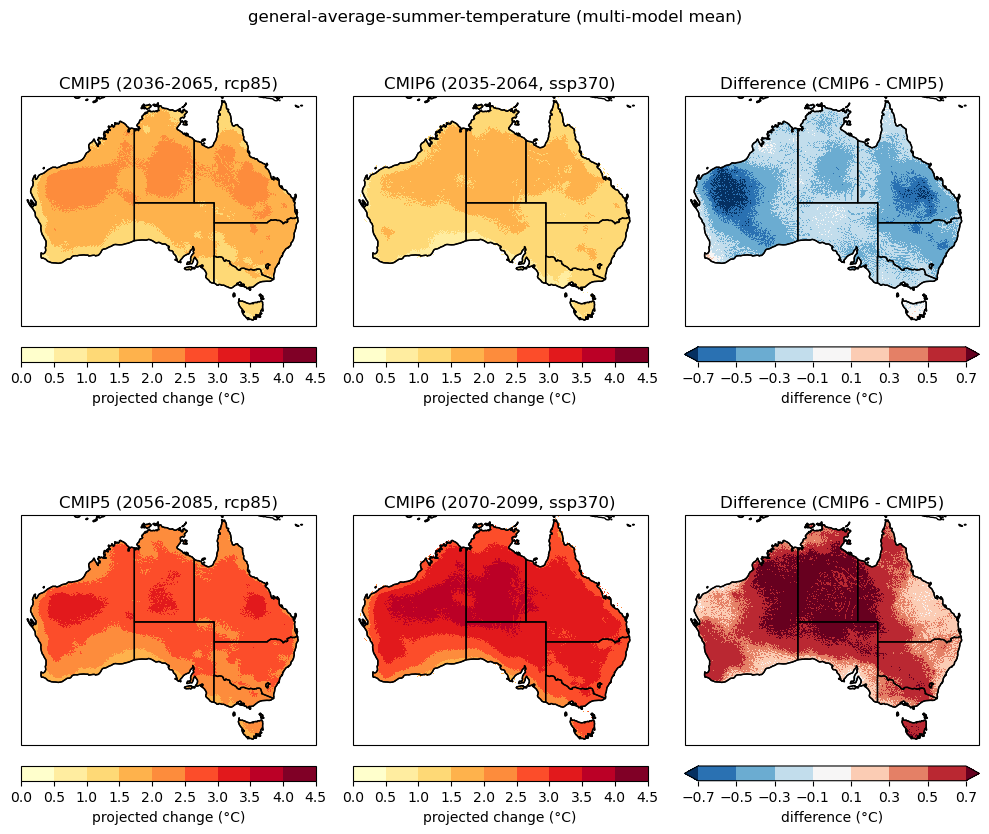

In [22]:
plot_comparison(
    'general-average-summer-temperature',
    'ssp370',
    np.arange(0, 5.0, 0.5),
    [-0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7],
    'YlOrRd',
    extend='neither'
)

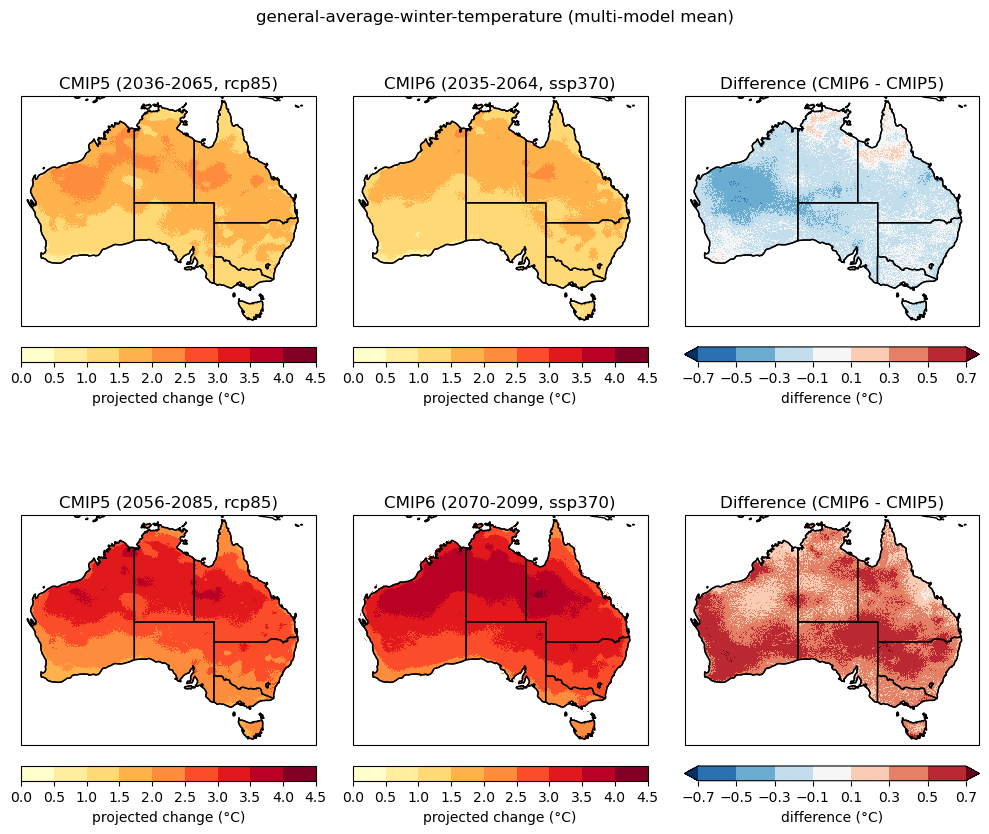

In [23]:
plot_comparison(
    'general-average-winter-temperature',
    'ssp370',
    np.arange(0, 5.0, 0.5),
    [-0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7],
    'YlOrRd',
    extend='neither'
)

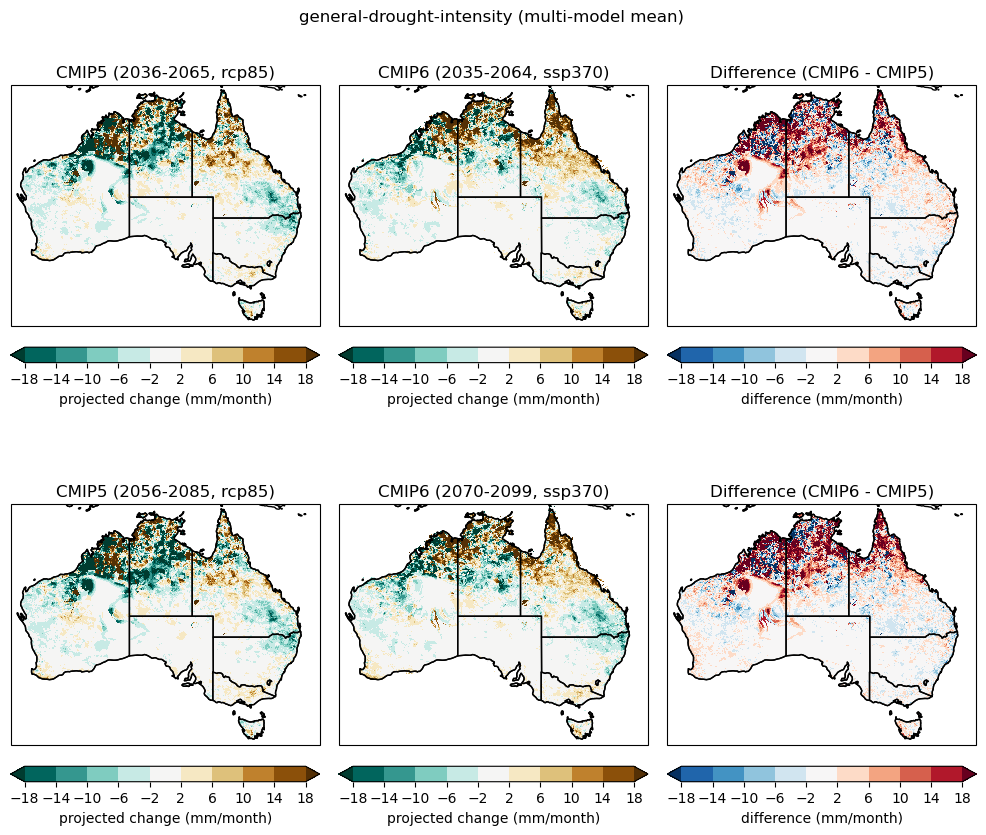

In [24]:
plot_comparison(
    'general-drought-intensity',
    'ssp370',
    np.arange(-18, 19, 4),
    np.arange(-18, 19, 4),
    'BrBG_r',
    extend='both',
)

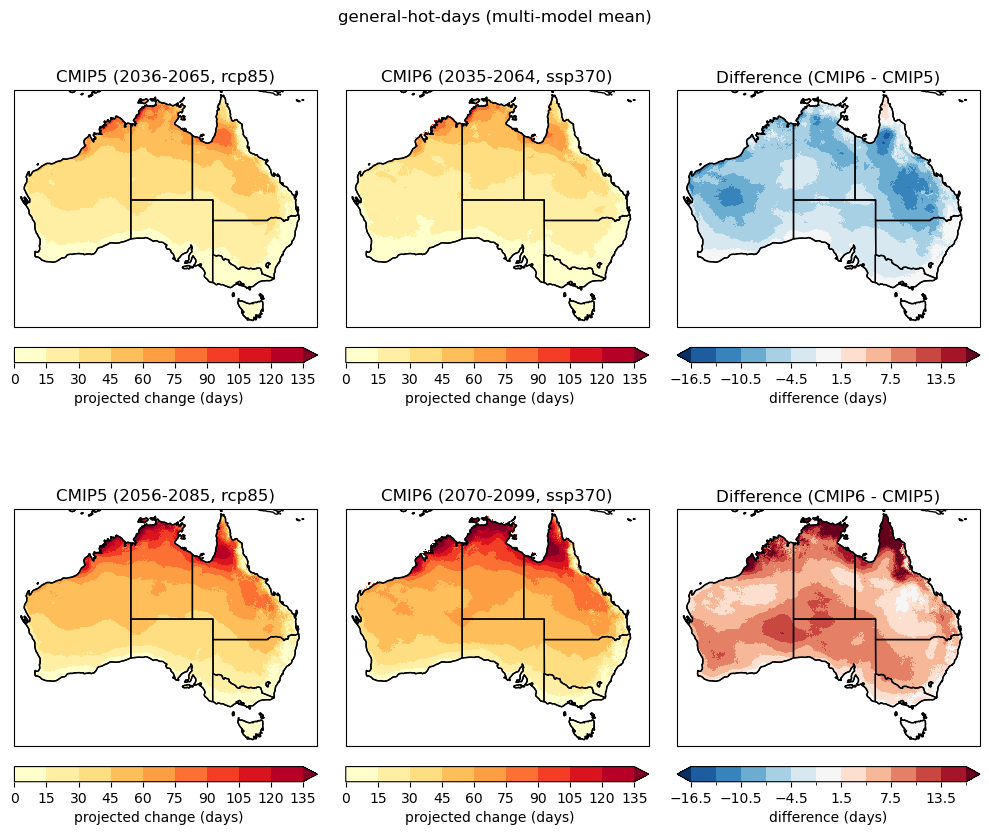

In [25]:
plot_comparison(
    'general-hot-days',
    'ssp370',
    np.arange(0, 150, 15),
    np.arange(-16.5, 17, 3),
    'YlOrRd',
    extend='max',
)

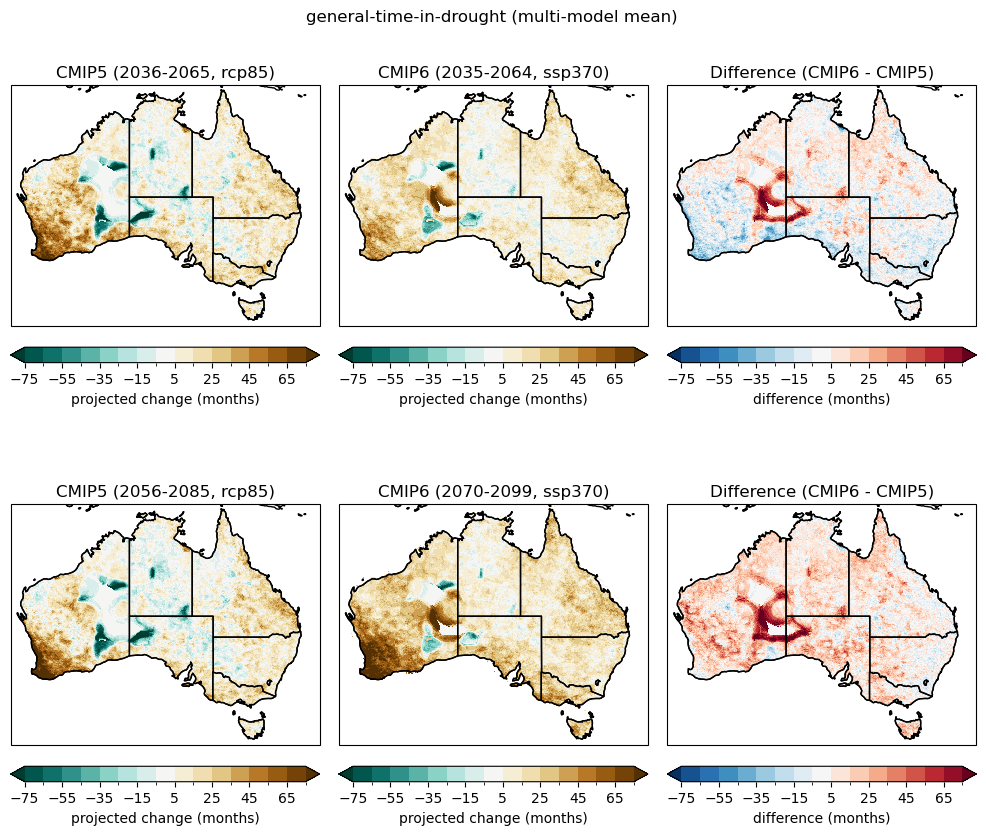

In [26]:
plot_comparison(
    'general-time-in-drought',
    'ssp370',
    np.arange(-75, 76, 10),
    np.arange(-75, 76, 10),
    'BrBG_r',
    extend='both',
)

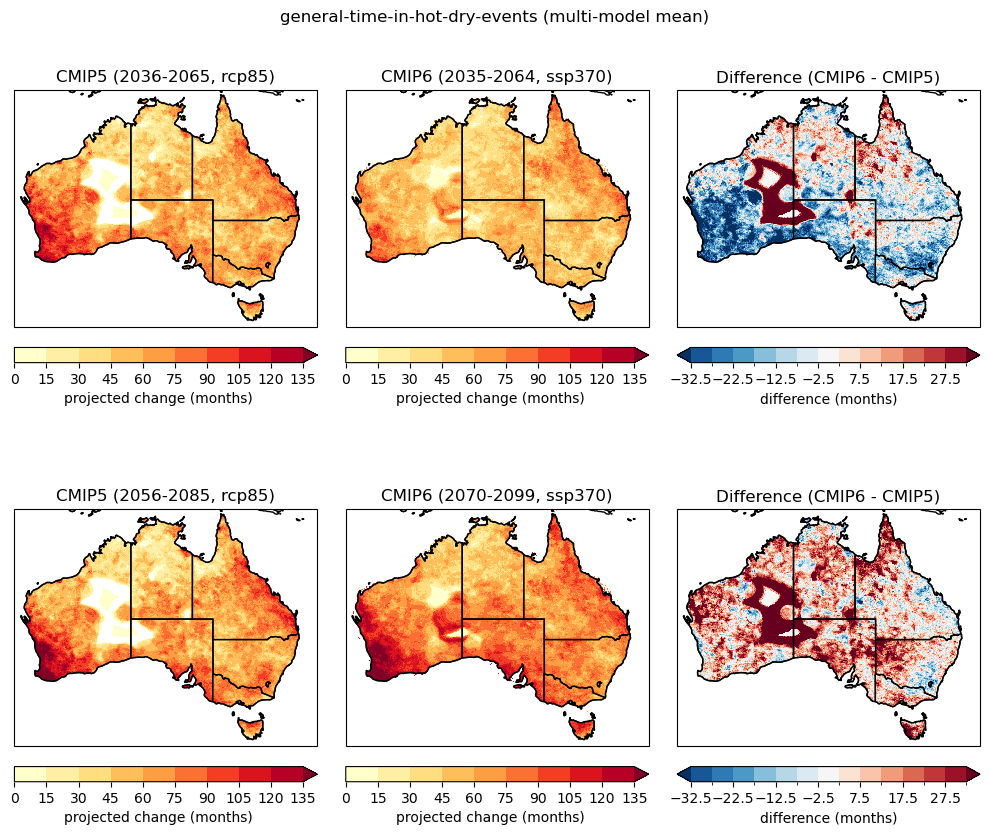

In [27]:
plot_comparison(
    'general-time-in-hot-dry-events',
    'ssp370',
    np.arange(0, 150, 15),
    np.arange(-32.5, 33, 5),
    'YlOrRd',
    extend='max',
)

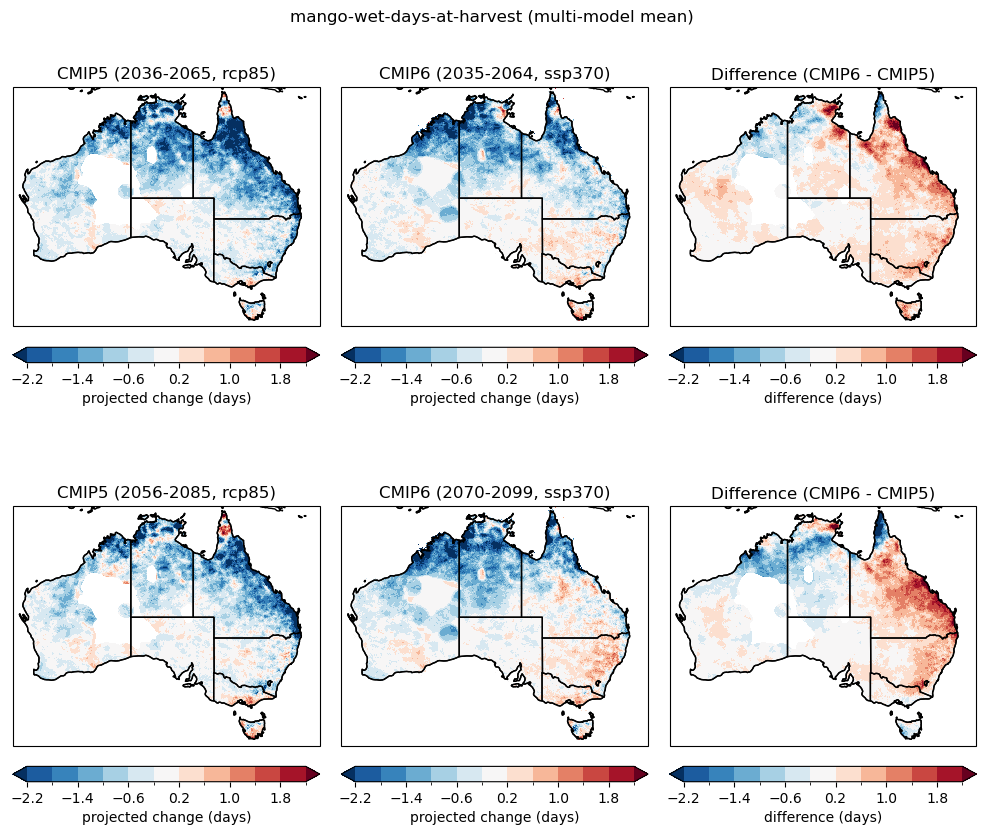

In [28]:
plot_comparison(
    'mango-wet-days-at-harvest',
    'ssp370',
    np.arange(-2.2, 2.3, 0.4),
    np.arange(-2.2, 2.3, 0.4),
    'RdBu_r',
    extend='both',
)

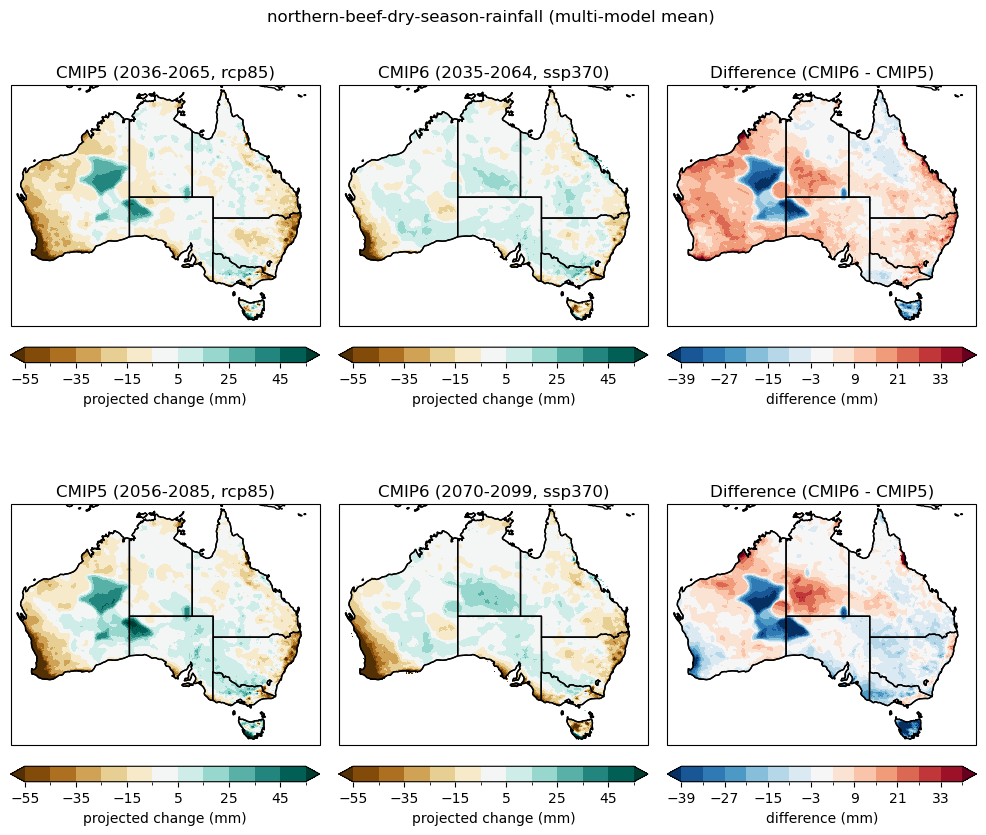

In [29]:
plot_comparison(
    'northern-beef-dry-season-rainfall',
    'ssp370',
    np.arange(-55, 56, 10),
    np.arange(-39, 40, 6),
    'BrBG',
    extend='both',
)

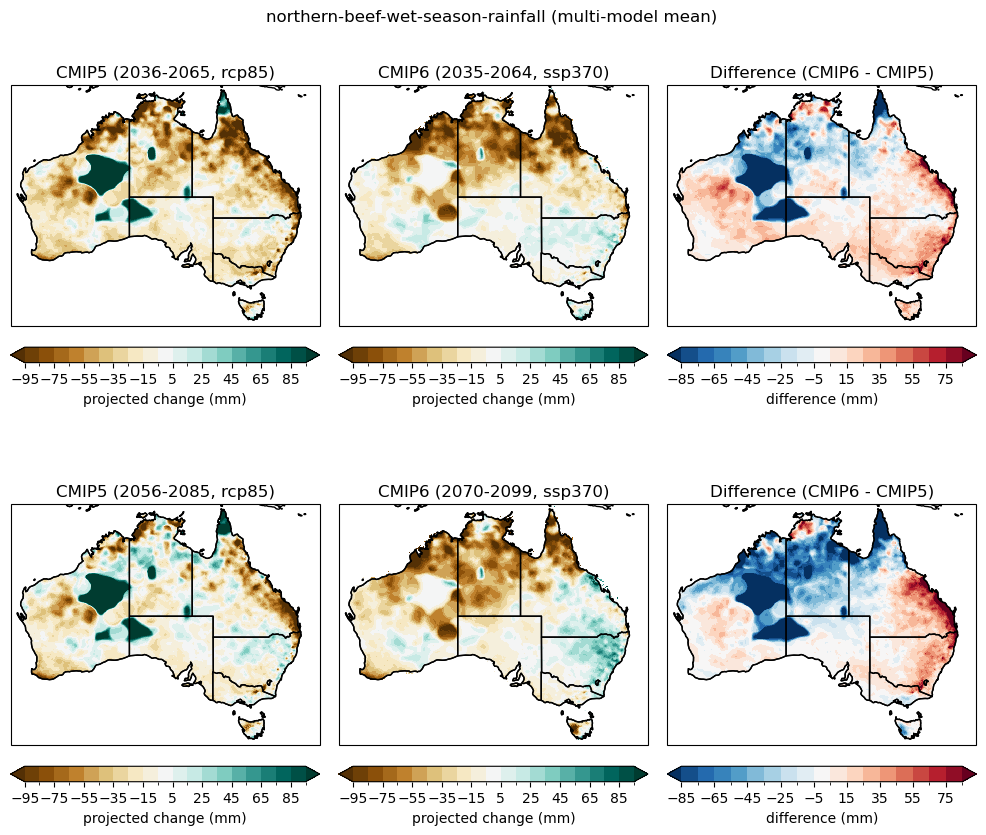

In [30]:
plot_comparison(
    'northern-beef-wet-season-rainfall',
    'ssp370',
    np.arange(-95, 96, 10),
    np.arange(-85, 86, 10),
    'BrBG',
    extend='both',
)

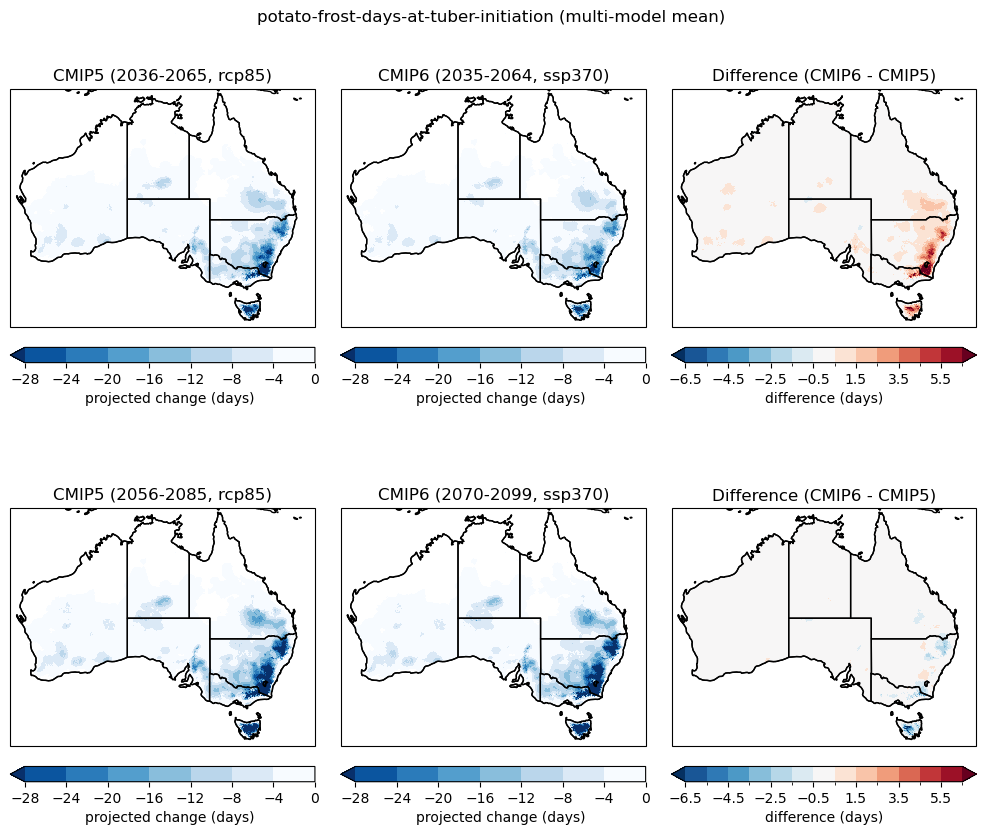

In [31]:
plot_comparison(
    'potato-frost-days-at-tuber-initiation',
    'ssp370',
    np.arange(-28, 1, 4),
    np.arange(-6.5, 6.6, 1),
    'Blues_r',
    extend='min',
)